In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch

In [ ]:
# DataFrame
# pandas에서는 행렬로 구성되어있는 데이터 세트를 다루기 위해 DataFrame 이라는 자료형을 활용한다.

# DataFrame 선언 방법
# 1. 딕셔너리
data1 = {'숫자': [1,2,3,4],
        '소문자': ['a','b','c','d'],
        '대문자':['A','B','C','D']}
print(data1)

# 2. 각각 선언
data = torch.arange(1,10,1)
data = data.view(3,3)
data = data.numpy()
rows = ['id1', 'id2', 'id3']
columns = ['feature1','feature2','feature3']

dataframe = pd.DataFrame(data, index = rows, columns = columns)
print(dataframe)

# Series
# index와 데이터로만 구성된 자료형이다
data = pd.Series([1,2,3,4], index = ['a','b','c','d'])
# 딕셔너리를 통해서도 선언이 가능하다

{'숫자': [1, 2, 3, 4], '소문자': ['a', 'b', 'c', 'd'], '대문자': ['A', 'B', 'C', 'D']}
     feature1  feature2  feature3
id1         1         2         3
id2         4         5         6
id3         7         8         9


In [ ]:
# Pandas에서 자주 사용되는 로직들

# 1. 결측값 탐색 및 제거
# 해당 로직들은 변수 형태로 선언해주어야 함 (함수만 실행해서는 drop된 결과가 저장되지 않음)
sample = pd.DataFrame(np.array([[None, 2, 3],[4,5,6],[7,None,None],[10,11,12]]), index = [1,2,3,4], columns = ['f1','f2','f3'])
# 열 별로 결측치가 몇 개인지 계산 후에 반환
sample.isnull().sum()
# 특정 열에서 결측치가 있는 행만 추출
sample[sample.f1.isnull()]
# 결측치가 있는 행 제거. axis = 1 일 경우 결측치가 있는 열 제거
sample.dropna(axis=0)
# 평균치로 채우기, 'ffill', 'bfill' 앞뒤에 있는 값으로 채우기, 그냥 값만 입력시 특정값으로 채우기
sample.fillna(sample.mean())

# 2. 특정 행 또는 열 추출
# df.loc[:, 'name'] 또는 df.iloc[index]을 사용
# 행과 열 추출: df.loc['row_name', 'col_name']
# 모든 행, 특정 열 추출: df.loc[:, ['col1', 'col2']]
# 여러 열을 데이터프레임으로 추출: df.loc[[column1, column2]]

'''
데이터 인덱싱 심화

1. 열 인덱싱
df['칼럼이름']: 하나의 열만 인덱싱
df[['칼럼이름']]: 하나의 열만 인덱싱 하면서 데이터프레임모양으로 출력
df[['칼럼이름1', '칼럼이름2']]: 여러 개의 열을 데이터프레임모양으로 인덱싱

2. 행 인덱싱
- 행인덱싱은 항상 슬라이싱 형식으로 가져오기 ex) df[1:3]
- 단일 행을 가져오려면 슬라이싱 형태로 만들어서 가져오기 ex) df[3:4]
- 문자 라벨로 인덱싱할때는 끝라벨 포함 ex) df['a':'c']
- 부분배열 불가능 ex)df[1,3,5]

3. 불리언 인덱싱
시리즈 인덱싱 : f1[f1 == 1200]
df['순위'] < 3 : 불리언의 나열로 반환
df[(df['색깔'] == '노랑') | (df['순위'] == 1)] : 데이터프레임으로 반환

4. loc, iloc : loc은 이름, iloc은 인덱스
열 가져오기:  df.loc[:,칼럼이름], df.iloc[:,칼럼번호]
행 가져오기: df.loc[행이름] df.loc[[행여러개]] df.loc[행슬라이싱]
행, 열 둘 다 가져오기: df.loc[ 행 , 열 ]

5. 조건에 따라 값 바꾸기
df.loc[조건, 열 이름] = 바꿀 값
df.replace('현재 문자열', '대체 문자열')

'''
# 3. 데이터 삭제
# 열 삭제: df.drop('열이름', axis=1)
# 행 삭제: df.drop('행이름', axis=0)


# 4. 데이터 추가
# 열 추가: df['열 이름'] = 값
# 행 추가: df.loc['행 이름'] = 값


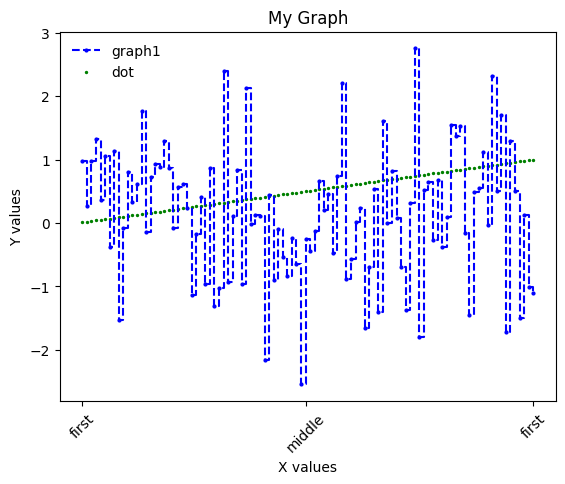

In [ ]:
# 정제한 데이터를 시각화하기
# 데이터
x = np.arange(1, 101)
y1 = torch.randn(100)
y1 = y1.numpy()
y2 = np.arange(1, 101)/100

# 가장 기본적인 함수 : plt.plot(x, y)
plt.plot(x, y1)
plt.scatter(x, y1)

# 중첩하여 생성도 가능하다.
plt.plot(x, y2)
plt.close() # 초기화

# plt.plot()에 여러가지 옵션 넣기
# linestyle : '--', ' ', '-.', ':', '-'
# marker : . o v ^ 등등 다양하다
# drawstyle : default, step-pre, steps-post 등 다양하다.
# label : legend에 나타날 이름
# color : 'k', 'b', 'r', 'g' 등
# plt.legend(loc = 'best', frameon = True, fontsize = 10)
plt.plot(x, y, linestyle = '--', marker = 'o', markersize = 2, color = 'b', drawstyle = 'steps-post', label = 'graph1')
plt.title('My Graph')
plt.xlabel('X values')
plt.ylabel('Y values')
plt.xticks([1, 50, 100], ['first', 'middle', 'first'], rotation = 45, fontsize = 10)

# 산포도
plt.scatter(x, y2, color = 'g', s = 2, label = 'dot')
plt.legend(loc = 'best', frameon = False, fontsize = 10)



'\nfig = plt.figure()\nax1 = fig.add_subplot(2,2,1)\n'

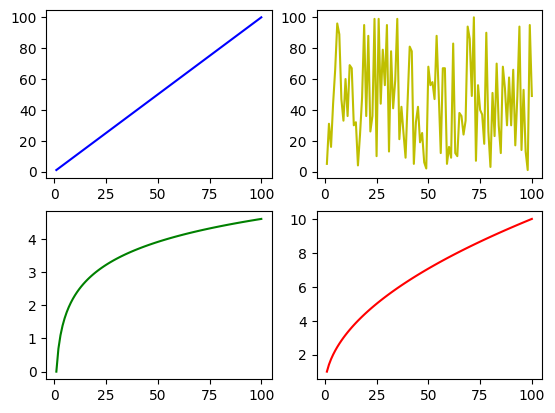

In [ ]:
# 여러 개의 함수를 띄워야 할 경우
x = np.arange(1, 101)
y1 = x
y2 = torch.randint(1,101, (100,))
y3 = torch.log(torch.FloatTensor(x))
y4 = torch.pow(torch.FloatTensor(x), 1/2)

fig = plt.figure()
a = fig.add_subplot(2,2,1)
plt.plot(x, y1, color = 'b')

b = fig.add_subplot(2,2,2)
plt.plot(x, y2, color = 'y')

c = fig.add_subplot(2,2,3)
plt.plot(x, y3, color = 'g')

d = fig.add_subplot(2,2,4)
plt.plot(x, y4, color = 'r')

'''
fig = plt.figure()
ax1 = fig.add_subplot(2,2,1)
'''

In [ ]:
# 실제 데이터를 전처리하여 시각화해보기
# kaggle 데이터 세트를 다운받기 위해서는 사이트로 들어가서 자신의 API키와 회원정보가 입력되어 있는 kaggle.json을 받아야 한다.
from google.colab import files
!pip install -q kaggle
files.upload()


Saving kaggle.json to kaggle.json


{'kaggle.json': b'{"username":"kimjaewoo0103","key":"8d5c35bc42ede00ddc711b630e3ae723"}'}

In [ ]:
# 다운로드 방법 1 : content 디렉토리 외부에 다운로드
import kagglehub
# 디렉토리 생성
!mkdir -p ~/.kaggle
# 생성한 디렉토리 안으로 kaggle.json 복사
!cp kaggle.json ~/.kaggle/
# 접근 권한 (사용자만) 설정
!chmod 600 ~/.kaggle/kaggle.json

path = kagglehub.dataset_download("harshadapatil31/student-performance-and-study-habits-dataset")
data = pd.read_csv(path)
data.head()



In [ ]:
# 다운로드 방법 2 : content 디렉토리에 다운로드
!kaggle datasets download harshadapatil31/student-performance-and-study-habits-dataset
!unzip -q student-performance-and-study-habits-dataset.zip #-q는 진행상황 숨김

data = pd.read_csv("/content/student_performance_dataset.csv")
data.head()

Dataset URL: https://www.kaggle.com/datasets/harshadapatil31/student-performance-and-study-habits-dataset
License(s): CC0-1.0
student-performance-and-study-habits-dataset.zip: Skipping, found more recently modified local copy (use --force to force download)
replace student_performance_dataset.csv? [y]es, [n]o, [A]ll, [N]one, [r]ename: y


,student_id,gender,study_time_hours,attendance_percent,sleep_hours,parental_education,internet_access,extracurricular_activities,part_time_job,previous_grade,final_exam_score,final_grade
0,1,Male,4.0,98.0,6.5,Bachelors,Yes,Yes,No,76.9,100.0,A
1,2,Female,6.3,100.0,5.7,High School,Yes,Yes,Yes,75.5,100.0,A
2,3,Male,4.9,85.3,7.9,Bachelors,Yes,No,Yes,88.5,97.3,A
3,4,Male,2.6,77.5,8.0,NaN,Yes,Yes,No,85.1,83.8,B
4,5,Male,2.2,89.6,4.6,Bachelors,Yes,No,Yes,61.8,68.3,D


In [ ]:
data.shape
data.head()

,student_id,gender,study_time_hours,attendance_percent,sleep_hours,parental_education,internet_access,extracurricular_activities,part_time_job,previous_grade,final_exam_score,final_grade
0,1,Male,4.0,98.0,6.5,Bachelors,Yes,Yes,No,76.9,100.0,A
1,2,Female,6.3,100.0,5.7,High School,Yes,Yes,Yes,75.5,100.0,A
2,3,Male,4.9,85.3,7.9,Bachelors,Yes,No,Yes,88.5,97.3,A
3,4,Male,2.6,77.5,8.0,NaN,Yes,Yes,No,85.1,83.8,B
4,5,Male,2.2,89.6,4.6,Bachelors,Yes,No,Yes,61.8,68.3,D


In [ ]:
df = data[['study_time_hours', 'final_exam_score']]
df.head()
df.isnull().sum()
df = df.dropna(axis = 0)
df.shape

(1000, 2)

In [ ]:
# 데이터 구경
print('data shape:',data.shape)
data.head()

data shape: (1000, 12)


,student_id,gender,study_time_hours,attendance_percent,sleep_hours,parental_education,internet_access,extracurricular_activities,part_time_job,previous_grade,final_exam_score,final_grade
0,1,Male,4.0,98.0,6.5,Bachelors,Yes,Yes,No,76.9,100.0,A
1,2,Female,6.3,100.0,5.7,High School,Yes,Yes,Yes,75.5,100.0,A
2,3,Male,4.9,85.3,7.9,Bachelors,Yes,No,Yes,88.5,97.3,A
3,4,Male,2.6,77.5,8.0,NaN,Yes,Yes,No,85.1,83.8,B
4,5,Male,2.2,89.6,4.6,Bachelors,Yes,No,Yes,61.8,68.3,D


/tmp/ipykernel_538/2491503296.py:15: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  x4 = x4.replace('Yes', 1)


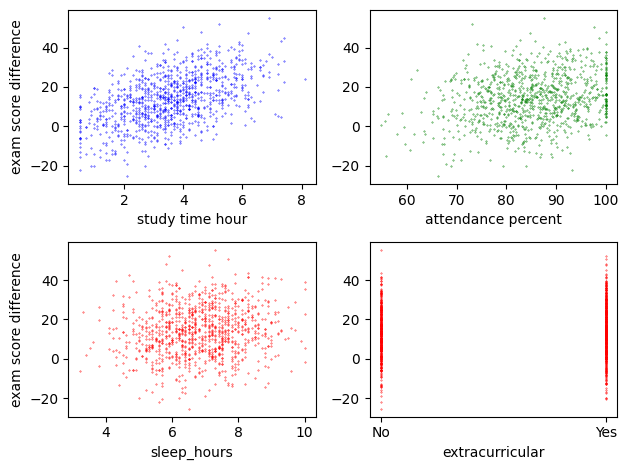

In [ ]:
# 1. 결측치 점검
data = pd.DataFrame(data)
# data.isnull().sum() # 분석하고자 하는 변수는 parental education이 아니므로 결측값은 없는 것으로 판정

# 2. 변수 분리
# 분석하고자 하는 독립변수 : study_time_hours, attendance_percent, sleep_hours, extracurricular_activities
# 분석하고자 하는 종속변수 : final_exam_score - previous_grade

y = data['final_exam_score'] - data['previous_grade']
x1 = data['study_time_hours']
x2 = data['attendance_percent']
x3 = data['sleep_hours']
x4 = data['extracurricular_activities']
x4 = x4.replace('No', 0)
x4 = x4.replace('Yes', 1)

# 3. 데이터 시각화
fig = plt.figure()
x1y = fig.add_subplot(2,2,1)
plt.scatter(x1, y, color = 'b', s = 0.1)
plt.xlabel('study time hour', size = 10)
plt.ylabel('exam score difference')

x2y = fig.add_subplot(2,2,2)
plt.scatter(x2, y, color = 'g', s = 0.1)
plt.xlabel('attendance percent', size =10)


x3y = fig.add_subplot(2,2,3)
plt.scatter(x3, y, color = 'r', s = 0.1)
plt.xlabel('sleep_hours')
plt.ylabel('exam score difference')

x4y = fig.add_subplot(2,2,4)
plt.scatter(x4, y, color = 'r', s = 0.1)
plt.xticks([0,1],['No','Yes'])
plt.xlabel('extracurricular')

plt.tight_layout()